# Energy App Review Sentiment Analysis — Exploratory Data Analysis

## Objective

This notebook explores the cleaned energy app review dataset.

The goal is to understand:

- Dataset size and structure
- Rating distribution
- Sentiment distribution
- App-wise review patterns
- Review length patterns
- Common words in positive and negative reviews

This EDA helps us understand the dataset before building machine learning models.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
data_path = "../data/processed/energy_app_reviews_cleaned.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (3070, 14)


,app_name,app_id,category,country,review_text,rating,review_date,thumbs_up_count,app_version,word_count,char_count,sentiment,clean_review_text,clean_word_count
0,Octopus Electroverse,energy.octopus.electricjuice.android,EV Charging / Energy Mobility,gb,"Good app, but why does the map always default to Charing Cross? It would be better if there were choices - default/h...",4,2026-05-30 09:56:07,0,2026.05.12,24,133,Positive,good app map always default charing cross would better choice default home last used,14
1,Octopus Electroverse,energy.octopus.electricjuice.android,EV Charging / Energy Mobility,gb,fantastic,5,2026-05-29 03:06:33,0,2026.05.05,1,9,Positive,fantastic,1
2,Octopus Electroverse,energy.octopus.electricjuice.android,EV Charging / Energy Mobility,gb,I'll be honest and say when I decided to go for an Electric Car I was very nervous regarding charging and the networ...,5,2026-05-27 18:31:56,0,2026.05.05,47,259,Positive,honest say decided go electric car nervous regarding charging network support however installing app game changer re...,22
3,Octopus Electroverse,energy.octopus.electricjuice.android,EV Charging / Energy Mobility,gb,"The app seems fine, and the support is excellent! I had a problem with my account, not being able to log in, and I c...",5,2026-05-27 10:23:39,0,2026.05.05,45,212,Positive,app seems fine support excellent problem account able log could reply email answer human sorted thanks ryan l,18
4,Octopus Electroverse,energy.octopus.electricjuice.android,EV Charging / Energy Mobility,gb,Very easy and fast to use also it covers a wide range of charge points,5,2026-05-27 05:55:17,0,2026.05.05,15,70,Positive,easy fast use also cover wide range charge point,9


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3070 entries, 0 to 3069
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   app_name           3070 non-null   str  
 1   app_id             3070 non-null   str  
 2   category           3070 non-null   str  
 3   country            3070 non-null   str  
 4   review_text        3070 non-null   str  
 5   rating             3070 non-null   int64
 6   review_date        3070 non-null   str  
 7   thumbs_up_count    3070 non-null   int64
 8   app_version        2880 non-null   str  
 9   word_count         3070 non-null   int64
 10  char_count         3070 non-null   int64
 11  sentiment          3070 non-null   str  
 12  clean_review_text  3070 non-null   str  
 13  clean_word_count   3070 non-null   int64
dtypes: int64(5), str(9)
memory usage: 335.9 KB


In [4]:
missing_values = df.isnull().sum().sort_values(ascending=False)
missing_values

app_version          190
app_name               0
category               0
country                0
review_text            0
app_id                 0
rating                 0
review_date            0
thumbs_up_count        0
word_count             0
char_count             0
sentiment              0
clean_review_text      0
clean_word_count       0
dtype: int64

In [5]:
rating_counts = df["rating"].value_counts().sort_index()
rating_counts

rating
1    1229
2     210
3     220
4     234
5    1177
Name: count, dtype: int64

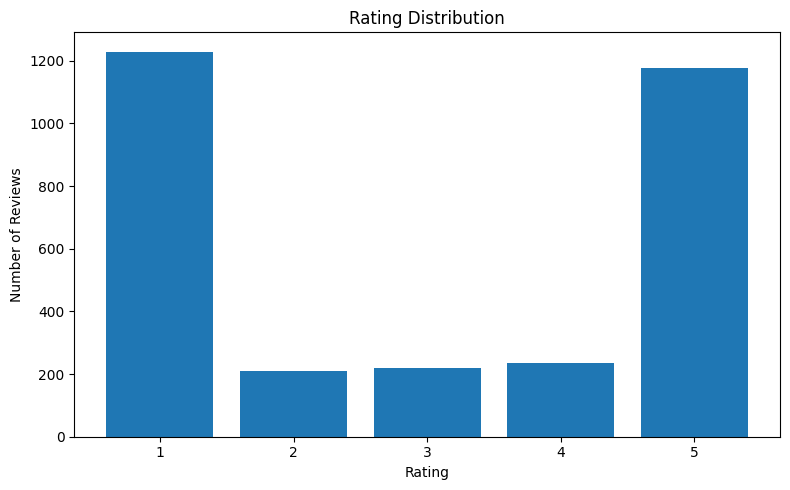

In [6]:
plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index.astype(str), rating_counts.values)
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "rating_distribution.png", dpi=300)
plt.show()

In [7]:
sentiment_counts = df["sentiment"].value_counts()
sentiment_counts

sentiment
Negative    1439
Positive    1411
Neutral      220
Name: count, dtype: int64

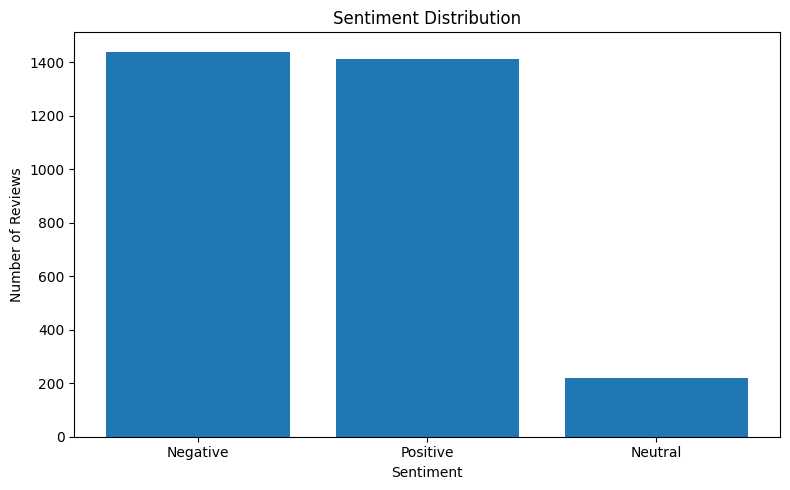

In [8]:
plt.figure(figsize=(8, 5))
plt.bar(sentiment_counts.index, sentiment_counts.values)
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "sentiment_distribution.png", dpi=300)
plt.show()

In [9]:
app_counts = df["app_name"].value_counts()
app_counts

app_name
Hive                    494
Octopus Electroverse    486
E.ON Myline             485
PlugShare               485
ScottishPower           479
Shell                   449
E.ON Next Home          103
Vattenfall InCharge      89
Name: count, dtype: int64

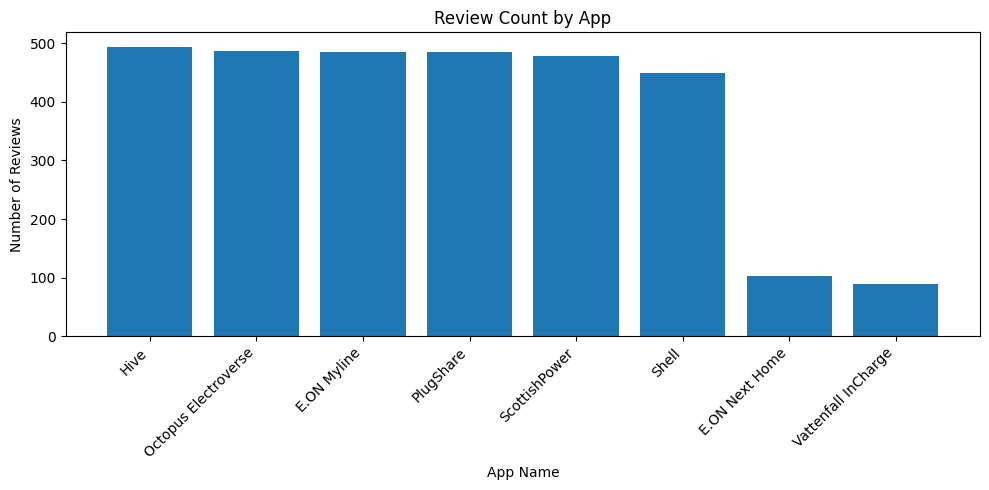

In [10]:
plt.figure(figsize=(10, 5))
plt.bar(app_counts.index, app_counts.values)
plt.title("Review Count by App")
plt.xlabel("App Name")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "review_count_by_app.png", dpi=300)
plt.show()

In [11]:
avg_rating_by_app = (
    df.groupby("app_name")["rating"]
    .mean()
    .sort_values(ascending=False)
)

avg_rating_by_app

app_name
PlugShare               3.997938
Octopus Electroverse    3.802469
Shell                   3.316258
ScottishPower           2.812109
E.ON Next Home          2.330097
Vattenfall InCharge     2.168539
E.ON Myline             2.144330
Hive                    2.093117
Name: rating, dtype: float64

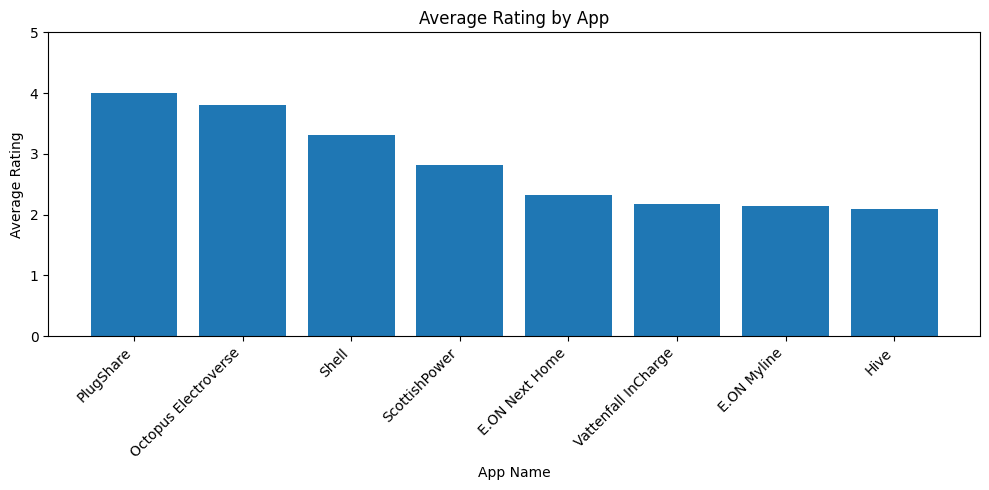

In [12]:
plt.figure(figsize=(10, 5))
plt.bar(avg_rating_by_app.index, avg_rating_by_app.values)
plt.title("Average Rating by App")
plt.xlabel("App Name")
plt.ylabel("Average Rating")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 5)
plt.tight_layout()

plt.savefig(FIGURES_DIR / "average_rating_by_app.png", dpi=300)
plt.show()

In [13]:
df[["word_count", "clean_word_count"]].describe()

,word_count,clean_word_count
count,3070.000000,3070.000000
mean,22.574267,12.910749
std,23.030775,13.062518
min,1.000000,1.000000
25%,6.000000,4.000000
50%,14.000000,8.000000
75%,31.000000,18.000000
max,171.000000,86.000000


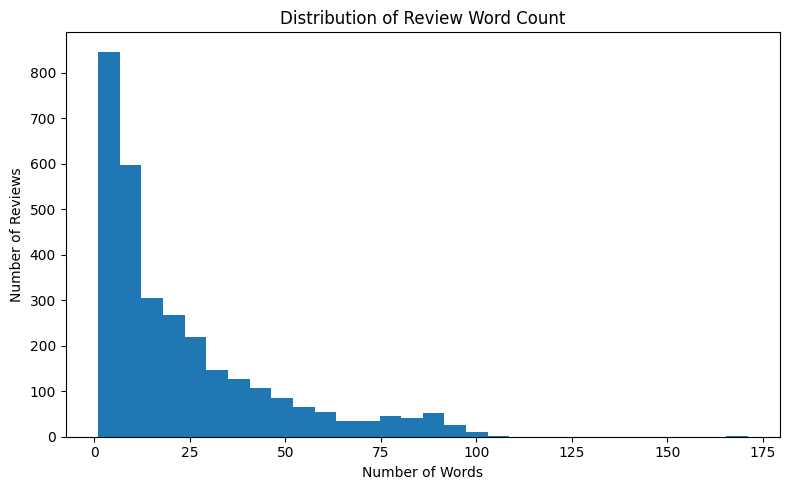

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(df["word_count"], bins=30)
plt.title("Distribution of Review Word Count")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "review_word_count_distribution.png", dpi=300)
plt.show()

In [16]:
length_by_sentiment = (
    df.groupby("sentiment")["clean_word_count"]
    .mean()
    .sort_values(ascending=False)
)

length_by_sentiment

sentiment
Neutral     17.650000
Negative    16.799166
Positive     8.206237
Name: clean_word_count, dtype: float64

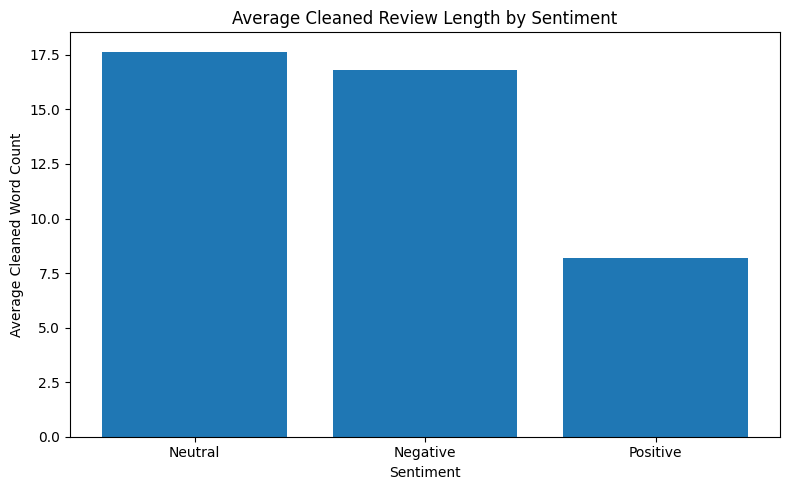

In [17]:
plt.figure(figsize=(8, 5))
plt.bar(length_by_sentiment.index, length_by_sentiment.values)
plt.title("Average Cleaned Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Cleaned Word Count")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "average_review_length_by_sentiment.png", dpi=300)
plt.show()

In [18]:
def get_top_words(text_series, top_n=20):
    vectorizer = CountVectorizer(
        max_features=1000,
        stop_words="english",
        ngram_range=(1, 1)
    )

    word_matrix = vectorizer.fit_transform(text_series)
    word_counts = word_matrix.sum(axis=0).A1

    words_df = pd.DataFrame({
        "word": vectorizer.get_feature_names_out(),
        "count": word_counts
    })

    return words_df.sort_values("count", ascending=False).head(top_n)

In [19]:
positive_words = get_top_words(
    df[df["sentiment"] == "Positive"]["clean_review_text"],
    top_n=20
)

positive_words

,word,count
49,app,507
260,easy,276
943,use,231
371,good,209
377,great,194
131,charging,174
130,charger,167
990,work,112
127,charge,111
286,ev,97


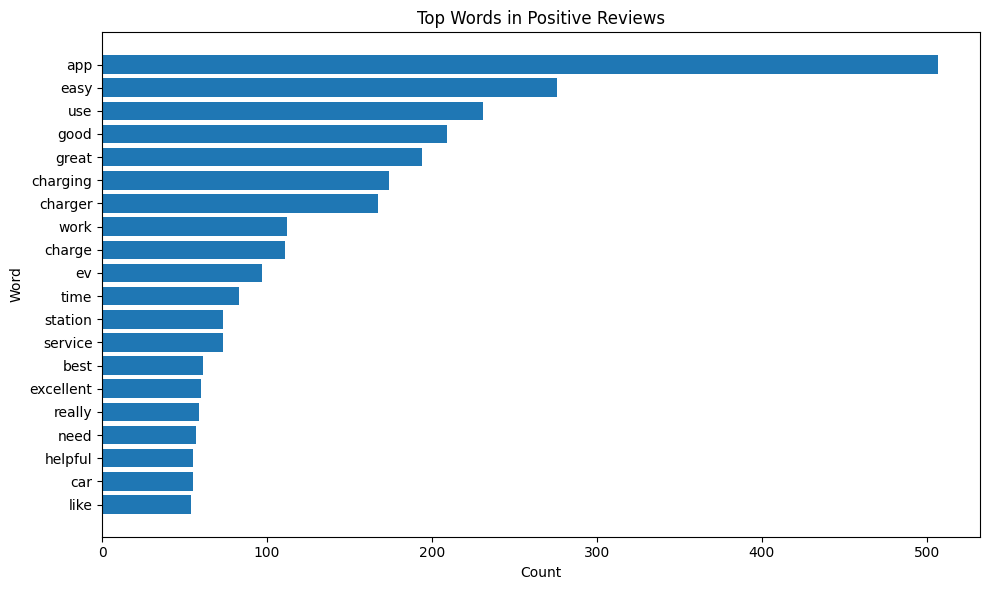

In [20]:
plt.figure(figsize=(10, 6))
plt.barh(positive_words["word"][::-1], positive_words["count"][::-1])
plt.title("Top Words in Positive Reviews")
plt.xlabel("Count")
plt.ylabel("Word")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "top_positive_words.png", dpi=300)
plt.show()

In [21]:
negative_words = get_top_words(
    df[df["sentiment"] == "Negative"]["clean_review_text"],
    top_n=20
)

negative_words

,word,count
45,app,1022
979,work,262
924,update,228
877,time,223
567,nu,199
142,charging,152
930,use,143
483,log,138
933,useless,131
124,card,128


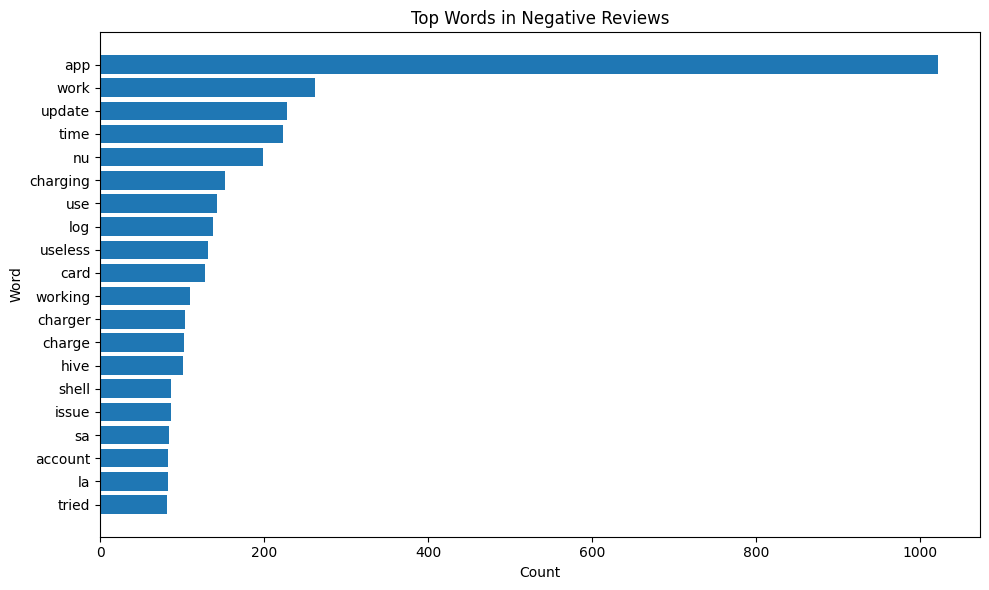

In [22]:
plt.figure(figsize=(10, 6))
plt.barh(negative_words["word"][::-1], negative_words["count"][::-1])
plt.title("Top Words in Negative Reviews")
plt.xlabel("Count")
plt.ylabel("Word")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "top_negative_words.png", dpi=300)
plt.show()

In [23]:
eda_summary = pd.DataFrame({
    "metric": [
        "total_reviews",
        "unique_apps",
        "average_rating",
        "average_word_count",
        "positive_reviews",
        "negative_reviews",
        "neutral_reviews"
    ],
    "value": [
        len(df),
        df["app_name"].nunique(),
        round(df["rating"].mean(), 2),
        round(df["word_count"].mean(), 2),
        (df["sentiment"] == "Positive").sum(),
        (df["sentiment"] == "Negative").sum(),
        (df["sentiment"] == "Neutral").sum()
    ]
})

eda_summary

,metric,value
0,total_reviews,3070.00
1,unique_apps,8.00
2,average_rating,2.97
3,average_word_count,22.57
4,positive_reviews,1411.00
5,negative_reviews,1439.00
6,neutral_reviews,220.00


In [24]:
eda_summary.to_csv("../reports/eda_summary.csv", index=False)
rating_counts.to_csv("../reports/rating_distribution.csv")
sentiment_counts.to_csv("../reports/sentiment_distribution.csv")
avg_rating_by_app.to_csv("../reports/average_rating_by_app.csv")
positive_words.to_csv("../reports/top_positive_words.csv", index=False)
negative_words.to_csv("../reports/top_negative_words.csv", index=False)

print("EDA summary files saved successfully.")

EDA summary files saved successfully.
